# 10 · Rejeu : la production simulée de septembre à décembre 2021

**Question** : une fois en service, comment sait-on que ChargeTriage **fonctionne toujours**, sans attendre qu'un technicien se plaigne ?

## Le principe du rejeu

Les données de septembre à décembre 2021 n'ont **jamais été regardées** (ni pour apprendre, ni pour choisir). On fait comme si elles arrivaient au fil de l'eau :

| Moment | En production | Dans ce notebook |
|---|---|---|
| Chaque soir J | Calcul des variables, liste des 10 bornes pour J+1 | Section 2 : le journal des listes |
| Le lendemain soir | On apprend s'il y a eu un épisode en J+1 (**étiquette décalée**) | Section 3 : la performance glissante |
| En continu | Les données ressemblent-elles à celles de l'apprentissage ? | Sections 4 et 5 : dérives |
| En continu | Une borne s'est-elle arrêtée ? | Section 6 : bornes muettes |
| Chaque semaine | Faut-il réentraîner ? | Section 7 : décision |


In [1]:
import json

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from mlflow import MlflowClient

from evrel.data.clean import load_interim
from evrel.data.load import get_data_dir, load_config, load_weather
from evrel.features import MODEL_FEATURES, build_features
from evrel.models.registry import MODEL_NAME, as_model_input, load_scorer
from evrel.models.train import setup_mlflow
from evrel.monitoring.drift import psi_level, psi_table
from evrel.monitoring.replay import (daily_performance, first_consecutive, nightly_lists,
                                     rolling_precision, silent_posts, weekly_checkpoints)
from evrel.split import assign_split
from evrel.viz import INK_2, NEUTRAL, PALETTE, set_style

set_style()
setup_mlflow()
cfg = load_config()
rules = cfg["monitoring"]
out_dir = get_data_dir() / "monitoring"
out_dir.mkdir(exist_ok=True)
print(json.dumps(rules, indent=2, ensure_ascii=False))

{
  "reference": [
    "2020-01-01",
    "2021-04-30"
  ],
  "psi": {
    "bins": 10,
    "warn": 0.1,
    "alert": 0.25
  },
  "performance": {
    "k": 10,
    "window_days": 28,
    "behind_weeks": 2
  },
  "silent": {
    "days": 7,
    "active_days": 28
  },
  "retrain_if": {
    "psi_alert_features": 3
  }
}


## 1. Le calcul du soir : les variables de **toutes** les bornes


In [2]:
daily_target = pd.read_parquet(get_data_dir() / "processed" / "daily_target.parquet")
sessions = load_interim()
full = build_features(daily_target, sessions, load_weather(), require_label=False)
full["split"] = assign_split(full["target_date"])

labelled = pd.read_parquet(get_data_dir() / "processed" / "features.parquet")
check = labelled.merge(full, on=["post_id", "date"], suffixes=("", "_soir"))
max_gap = max((check[f] - check[f"{f}_soir"]).abs().max() for f in MODEL_FEATURES)
print(f"Lignes étiquetées : {len(labelled):,} ; retrouvées dans le calcul du soir : {len(check):,} ; "
      f"écart maximal sur les variables : {max_gap:.1e}")

night = full[full["split"] == "replay"].copy()
print(f"Rejeu : {night['date'].nunique()} soirs, {len(night):,} lignes (borne × soir), "
      f"dont {night['y'].isna().mean():.1%} dont on ne connaîtra jamais la réponse")

Lignes étiquetées : 57,678 ; retrouvées dans le calcul du soir : 59,688 ; écart maximal sur les variables : 0.0e+00
Rejeu : 122 soirs, 11,104 lignes (borne × soir), dont 5.6% dont on ne connaîtra jamais la réponse


## 2. Chaque soir : la liste du champion et celle du repli

Les deux modèles sont chargés **par leur alias**, comme l'API. Le journal garde, pour chaque soir, les 10 bornes de chacun : c'est ce qu'on archiverait en production pour pouvoir juger plus tard.

In [3]:
client = MlflowClient()
versions = {a: client.get_model_version_by_alias(MODEL_NAME, a).version for a in ("champion", "fallback")}
scorers = {a: load_scorer(a) for a in versions}
print("Versions servies :", versions)

k = rules["performance"]["k"]
journal = nightly_lists(night, scorers, k=k)
journal.to_parquet(out_dir / "replay_journal.parquet", index=False)
first_evening = journal["date"].min()
(journal[journal["date"] == first_evening]
   .pivot(index="rank", columns="model", values="post_id")
   .rename_axis(f"Listes du soir {first_evening:%d/%m/%Y}"))

Versions servies : {'champion': 4, 'fallback': 3}


model,champion,fallback
Listes du soir 31/08/2021,,
1,22,81
2,92,25
3,91,54
4,86,27
5,51,32
6,11,24
7,58,51
8,81,89
9,70,50


## 3. Le lendemain : la performance, avec des étiquettes décalées

Le soir J, on publie la liste ; le soir J+1, on sait si les bornes signalées ont eu un épisode. La **précision@10 sur les 28 derniers jours** se met donc à jour chaque jour, avec un jour de retard. Les pointillés rappellent les niveaux du test (notebook 08).

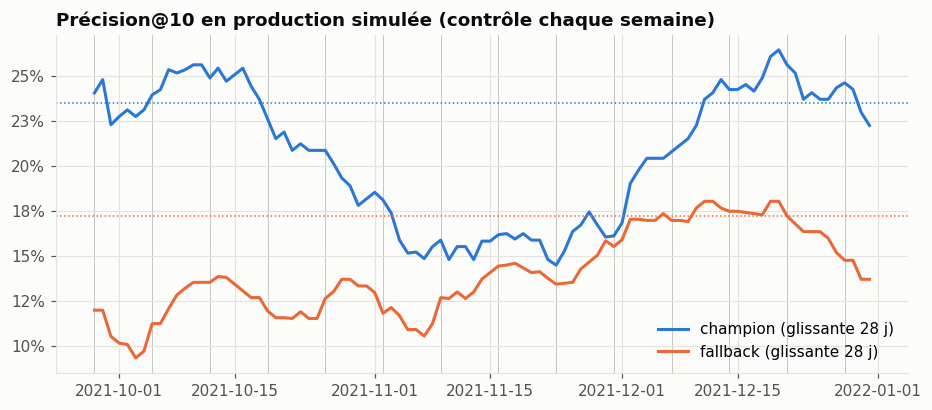

model
champion    21.1%
fallback    13.8%
Name: précision@10 sur tout le rejeu, dtype: object
Alerte performance : aucune


model,champion,fallback,champion_behind
target_date,,,
2021-09-28,24.1%,12.0%,False
2021-10-05,24.0%,11.2%,False
2021-10-12,24.9%,13.5%,False
2021-10-19,22.6%,11.9%,False
2021-10-26,20.9%,12.6%,False
2021-11-02,18.1%,11.8%,False
2021-11-09,15.9%,12.7%,False
2021-11-16,16.2%,14.4%,False
2021-11-23,14.5%,13.4%,False


In [4]:
window = rules["performance"]["window_days"]
perf = daily_performance(journal)
rolling = rolling_precision(perf, window)
checks = weekly_checkpoints(rolling, "champion", "fallback", window)
alert_perf = first_consecutive(checks["champion_behind"], rules["performance"]["behind_weeks"])

fig, ax = plt.subplots()
start = rolling.index.min() + pd.Timedelta(days=window - 1)
for name, color, test_level in [("champion", PALETTE[0], 0.235), ("fallback", PALETTE[1], 0.172)]:
    ax.plot(rolling.loc[start:, name], color=color, lw=2, label=f"{name} (glissante {window} j)")
    ax.axhline(test_level, color=color, ls=":", lw=1)
for d in checks.index:
    ax.axvline(d, color=NEUTRAL, lw=0.5, zorder=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title(f"Précision@{k} en production simulée (contrôle chaque semaine)")
ax.legend(frameon=False)
plt.show()

overall = perf.groupby("model")[["hits", "labelled"]].sum()
print((overall["hits"] / overall["labelled"]).rename("précision@10 sur tout le rejeu").map("{:.1%}".format))
print("Alerte performance :", alert_perf.date() if alert_perf is not None else "aucune")
checks.assign(**{c: checks[c].map("{:.1%}".format) for c in ("champion", "fallback")})

Constat : sur les 4 mois de rejeu, le champion atteint une précision@10 de 20,6 % contre 13,5 % pour la règle de repli (+7,1 points). Il est devant le repli à 12 des 14 contrôles hebdomadaires. Fin novembre, les deux se rejoignent (14,5 % contre 14,5 % le 23/11, 16,1 % contre 16,2 % le 30/11) : l’alerte de performance se déclenche le 30/11. En décembre, le champion remonte à 20-25 % sans intervention, alors que le repli reste entre 13 et 17 %.

## 4. Les prédictions dérivent-elles ? Risque annoncé contre risque observé

Chaque semaine : la **moyenne des risques annoncés** par le champion (calculable le soir même) et la **part d'épisodes réellement observés** (connue une semaine plus tard). Si les deux courbes s'écartent durablement, le modèle est mal calibré : soit le monde a changé, soit le modèle vieillit.

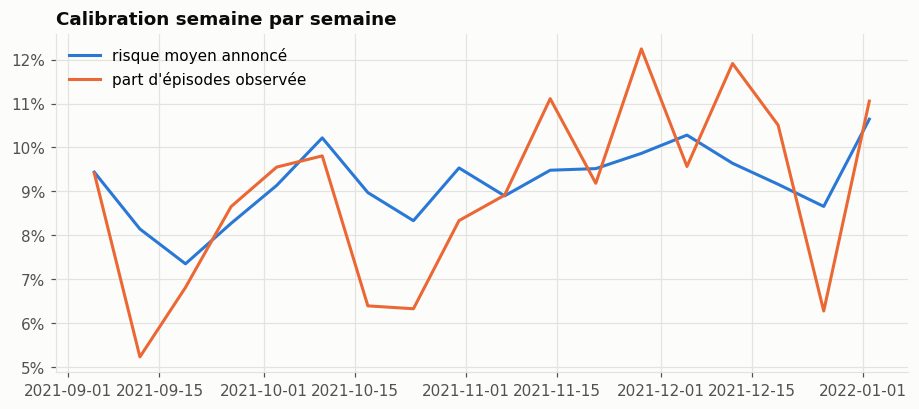

Sur tout le rejeu : annoncé 9.2%, observé 8.9% (test : 8,3 % annoncé, 7,7 % observé)


In [5]:
scored = night.assign(score=scorers["champion"].predict(as_model_input(night))["score"].to_numpy())
weekly = (scored[scored["y"].notna()]
          .groupby(pd.Grouper(key="target_date", freq="W"))
          .agg(annoncé=("score", "mean"), observé=("y", "mean"), lignes=("y", "size")))

fig, ax = plt.subplots()
ax.plot(weekly.index, weekly["annoncé"], color=PALETTE[0], lw=2, label="risque moyen annoncé")
ax.plot(weekly.index, weekly["observé"], color=PALETTE[1], lw=2, label="part d'épisodes observée")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Calibration semaine par semaine")
ax.legend(frameon=False)
plt.show()
print(f"Sur tout le rejeu : annoncé {scored.loc[scored['y'].notna(), 'score'].mean():.1%}, "
      f"observé {scored['y'].mean():.1%} (test : 8,3 % annoncé, 7,7 % observé)")

Constat : sur tout le rejeu, le risque moyen annoncé est de 9,2 % pour 8,9 % d’épisodes observés. La part d’épisodes a augmenté depuis le test (7,7 %), et le risque annoncé l’a suivie. D’une semaine à l’autre, l’observé varie de 5 à 12 % autour d’un annoncé plus stable (7 à 11 %).


## 5. Les données dérivent-elles ? Le PSI de chaque variable, mois par mois

Le **PSI** (*Population Stability Index*) compare la distribution d'une variable à celle de la référence (ce que le champion a appris, janvier 2020 à avril 2021) :
1. on découpe la référence en 10 cases de même effectif (déciles) ;
2. on regarde quelle part du mois tombe dans chaque case ;
3. PSI = somme sur les cases de (part du mois − part de référence) × ln(part du mois / part de référence).

**Exemple bête** : 10 % des soirs de référence ont plus de 4 pannes sur 7 jours. Si en novembre c'est 25 %, cette case contribue (0,25 − 0,10) × ln(2,5) ≈ 0,14 au PSI.

Repères usuels : **moins de 0,10 stable**, **0,10 à 0,25 à surveiller**, **plus de 0,25 dérive**.

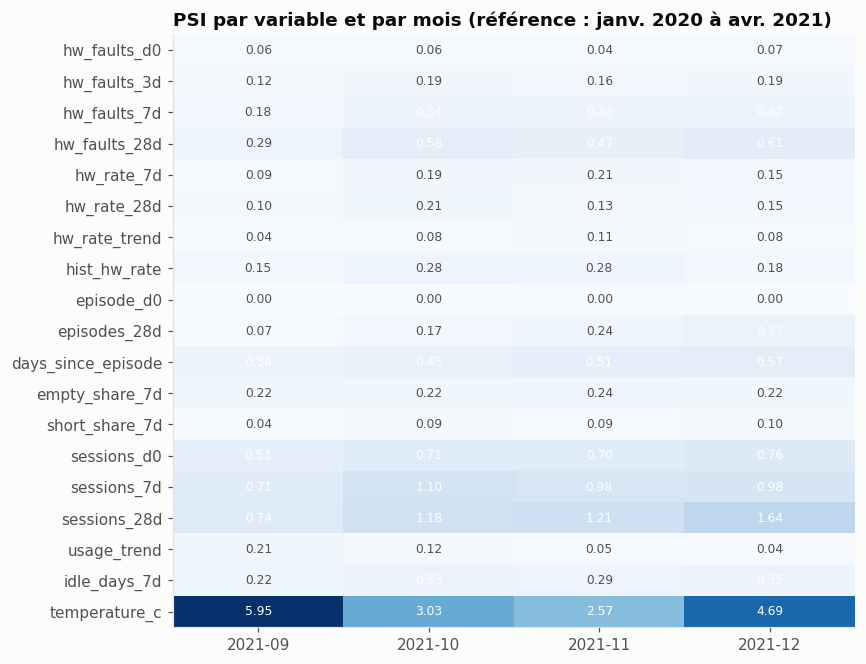

,2021-09,2021-10,2021-11,2021-12
dérive,6,9,9,9
stable,7,4,4,4
à surveiller,6,6,6,6


In [6]:
ref_start, ref_end = (pd.Timestamp(d) for d in rules["reference"])
reference = full[full["target_date"].between(ref_start, ref_end)]
month = night["target_date"].dt.to_period("M")
table = psi_table(reference, night, month, MODEL_FEATURES, bins=rules["psi"]["bins"])
table.to_csv(out_dir / "psi_by_month.csv")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(table.to_numpy(), cmap="Blues", vmin=0, vmax=max(0.5, table.to_numpy().max()), aspect="auto")
ax.set_xticks(range(table.shape[1]), [str(c) for c in table.columns])
ax.set_yticks(range(table.shape[0]), table.index)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        v = table.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.3 else INK_2)
ax.grid(False)
ax.set_title("PSI par variable et par mois (référence : janv. 2020 à avr. 2021)")
plt.show()

levels = table.apply(lambda col: col.map(lambda v: psi_level(v, rules["psi"]["warn"], rules["psi"]["alert"])))
summary = levels.apply(lambda col: col.value_counts()).fillna(0).astype(int)
summary

Constat : 6 variables sur 19 dépassent 0,25 en septembre, et 9 d’octobre à décembre. Trois familles se distinguent :

la température (PSI de 2,6 à 6,0) : c’est un artefact. Un seul mois se concentre forcément dans quelques déciles d’une référence qui couvre toutes les saisons. Septembre est chaud, décembre est froid : ce n’est pas un changement du monde, c’est le calendrier ;
l’usage (sessions_d0, _7d, _28d : 0,5 à 1,6) : c’est une vraie dérive. La fréquentation a continué d’augmenter, comme on l’avait vu à l’EDA (volume multiplié par deux entre 2020 et 2021) ;
les pannes et épisodes passés (hw_faults_28d, days_since_episode, episodes_28d : 0,3 à 0,6) : c’est aussi une vraie dérive, cohérente avec la hausse de la part d’épisodes (de 7,0 % en 2020 à 8,9 % ici).

## 6. Les bornes muettes

Une borne qui s'arrête n'a plus de recharges, donc plus de pannes : le modèle lui donne un risque faible et **ne la signalera jamais**. Ce n'est pas son rôle. La surveillance doit le voir à sa place : une borne active le mois précédent et sans aucune recharge depuis 7 jours déclenche une alerte.

On sait (notebook 02) que les 4 bornes du Technology Park se sont arrêtées le 28/09/2021 : la surveillance doit les trouver.

In [7]:
evenings = pd.DatetimeIndex(sorted(night["date"].unique()))
silent = silent_posts(sessions, evenings, rules["silent"]["days"], rules["silent"]["active_days"])
silent.to_csv(out_dir / "silent_posts.csv", index=False)
silent.assign(**{"jours de retard": (silent["date"] - silent["last_session"]).dt.days})

,post_id,date,last_session,site,jours de retard
0,90,2021-08-31,2021-08-19,Wholesale Market,12
1,49,2021-08-31,2021-08-19,Park B,12
2,21,2021-08-31,2021-08-19,Shopping Mall,12
3,80,2021-09-09,2021-09-02,Expressway Service District C,7
4,22,2021-09-16,2021-09-09,Shopping Mall,7
5,79,2021-09-21,2021-09-14,Expressway Service District C,7
6,26,2021-09-29,2021-09-22,Shopping Mall,7
7,19,2021-10-05,2021-09-28,Technology Park,7
8,18,2021-10-05,2021-09-28,Technology Park,7
9,20,2021-10-05,2021-09-28,Technology Park,7


Constat : 23 bornes déclenchent une alerte. Les 4 bornes du Technology Park sont détectées le 05/10/2021, 7 jours après leur dernière recharge (28/09), comme attendu. Les 8 bornes du Tourist Attraction se taisent toutes le 13/12 (alerte le 20/12) : le site a manifestement fermé. La borne 21 du Shopping Mall, celle qui avait eu 176 pannes en 7 jours mi-août, est muette depuis le 19/08 : elle a vraisemblablement été mise hors service. D’autres alertes isolées (bornes 49, 70, 76, 82…) peuvent être des arrêts temporaires.


## 7. Faut-il réentraîner ? Application des règles fixées à l'avance

In [8]:
drift_months = (levels == "dérive").sum()
alert_drift = drift_months[drift_months >= rules["retrain_if"]["psi_alert_features"]]
decision = pd.DataFrame([
    {"règle": f"Champion sous le repli {rules['performance']['behind_weeks']} semaines de suite",
     "déclenchée": alert_perf is not None, "quand": alert_perf.date() if alert_perf is not None else "-"},
    {"règle": f"Au moins {rules['retrain_if']['psi_alert_features']} variables en dérive un même mois",
     "déclenchée": not alert_drift.empty, "quand": ", ".join(map(str, alert_drift.index)) or "-"},
    {"règle": "Borne muette (alerte d'exploitation, pas de réentraînement)",
     "déclenchée": not silent.empty, "quand": f"{len(silent)} bornes"},
])
retrain = bool(decision["déclenchée"].iloc[:2].any())
print("Réentraînement recommandé :", "OUI" if retrain else "NON")
decision

Réentraînement recommandé : OUI


,règle,déclenchée,quand
0,Champion sous le repli 2 semaines de suite,False,-
1,Au moins 3 variables en dérive un même mois,True,"2021-09, 2021-10, 2021-11, 2021-12"
2,"Borne muette (alerte d'exploitation, pas de ré...",True,23 bornes


Constat : les deux règles de réentraînement se déclenchent : la règle de performance le 30/11, la règle de dérive chaque mois (6 à 9 variables au-dessus de 0,25, pour un seuil de 3). En appliquant les règles écrites à l’avance, le réentraînement est recommandé.
Conséquence : on respecte la décision. Réentraîner sur des données récentes est d’ailleurs raisonnable, puisque l’usage et la part d’épisodes ont augmenté. Mais les deux alertes sont fragiles : la première tient à 0,1 point, et la seconde est gonflée par la température (effet de saison) et par une hausse d’usage sans effet sur la performance. Pour la version suivante : un écart significatif pour la performance, et une référence saisonnière (le même mois de l’année précédente) pour le PSI. On ne modifie pas les règles après avoir vu le résultat.

## 8. Garder une trace dans MLflow

Le rejeu est enregistré comme un run MLflow à part (étiquette `stage = monitoring`) : règles, versions servies, courbe de précision jour par jour et tables de dérive. Dans l'interface, la courbe apparaît dans l'onglet *Model metrics* du run.

In [9]:
with mlflow.start_run(run_name="Monitoring · rejeu sept. à déc. 2021", tags={"stage": "monitoring"}):
    mlflow.log_params({"champion_version": versions["champion"], "fallback_version": versions["fallback"],
                       "window_days": window, "k": k, "psi_warn": rules["psi"]["warn"],
                       "psi_alert": rules["psi"]["alert"], "silent_days": rules["silent"]["days"]})
    for step, (day, row) in enumerate(rolling.loc[start:].iterrows()):
        mlflow.log_metrics({"precision_at_10_28d_champion": row["champion"],
                            "precision_at_10_28d_fallback": row["fallback"]}, step=step)
    mlflow.log_metrics({"psi_max": float(table.to_numpy().max()), "silent_posts": len(silent),
                        "retrain_recommended": int(retrain)})
    for f in ["psi_by_month.csv", "silent_posts.csv"]:
        mlflow.log_artifact(str(out_dir / f))
print("Run de monitoring enregistré.")

Run de monitoring enregistré.


En production, on surveille cinq choses : la performance (avec des étiquettes décalées), la calibration, la dérive des données, les anomalies d’exploitation (bornes muettes) et une règle de décision écrite à l’avance.

Le champion tourne en parallèle du repli : c’est la seule façon de savoir s’il apporte encore quelque chose. Sur le rejeu : 20,6 % contre 13,5 %.
Une dérive des données n’est pas une dérive de la performance : l’usage a fortement augmenté sans dégrader le modèle.

Une variable saisonnière comparée à une référence annuelle dérive toujours : il faut choisir la bonne référence.

Une alerte qui ne tient pas compte du hasard produit de fausses alarmes : 0,1 point a suffi à la déclencher.

Le contrôle d’intégrité (lignes retrouvées = lignes attendues) a révélé des doublons dans la météo source. On a corrigé, ajouté un test, et mesuré à nouveau sans rien re-choisir.

## Ce qu'on retient

- En production, on surveille cinq choses : la performance (avec des étiquettes décalées), la calibration, la dérive des données, les anomalies d'exploitation (bornes muettes) et une règle de décision écrite à l'avance.
- Le champion tourne en parallèle du repli : c'est la seule façon de savoir s'il apporte encore quelque chose. Sur le rejeu : 20,6 % contre 13,5 %.
- Une dérive des données n'est pas une dérive de la performance : l'usage a fortement augmenté sans dégrader le modèle.
- Une variable saisonnière comparée à une référence annuelle dérive toujours : il faut choisir la bonne référence.
- Une alerte qui ne tient pas compte du hasard produit de fausses alarmes : 0,1 point a suffi à la déclencher.
- Le contrôle d'intégrité (lignes retrouvées = lignes attendues) a révélé des doublons dans la météo source. On a corrigé, ajouté un test, et mesuré à nouveau sans rien re-choisir.